## Q1(a).

In [1]:
from sklearn.datasets import fetch_olivetti_faces

In [2]:
olivetti = fetch_olivetti_faces()

In [3]:
olivetti

{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
         0.1570248 ],
        [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
         0.15289256],
        [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
         0.15289256],
        ...,
        [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
         0.19008264],
        [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
         0.60330576],
        [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
         0.38429752]], shape=(400, 4096), dtype=float32),
 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
          0.3305785 , 0.30578512],
         [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
          0.338843  , 0.3140496 ],
         [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
          0.338843  , 0.29752067],
         ...,
         [0.21487603, 0.20661157, 0.2231405 , ...

In [4]:
y=olivetti['target']

In [5]:
x=olivetti['data']

In [6]:
images=olivetti['images']

In [7]:
x

array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], shape=(400, 4096), dtype=float32)

## Roll Number is M26MER008

In [8]:
import numpy as np
import time

In [9]:
SEED=26008

In [10]:
rng=np.random.default_rng(SEED)

In [11]:
train_idx=[]
val_idx=[]
test_idx=[]

In [12]:
for identity in range(40):
    identity_indices= np.flatnonzero(y==identity)
    shuffled_indices= rng.permutation(identity_indices)
    print(shuffled_indices)
    train_idx.extend(shuffled_indices[:6])
    val_idx.extend(shuffled_indices[6:8])
    test_idx.extend(shuffled_indices[8:10])

[6 3 9 8 7 2 5 0 1 4]
[11 19 18 10 13 16 14 12 17 15]
[25 23 24 29 28 20 22 26 21 27]
[31 35 38 30 33 39 37 34 36 32]
[48 44 42 49 45 46 43 41 40 47]
[52 50 51 54 59 55 57 58 53 56]
[69 64 65 66 63 61 62 60 67 68]
[72 79 76 74 70 75 71 78 73 77]
[85 87 82 86 80 89 83 88 84 81]
[91 99 98 97 94 90 93 92 95 96]
[108 106 104 100 105 109 103 101 107 102]
[114 115 113 110 111 116 118 119 117 112]
[126 124 128 127 122 125 129 121 123 120]
[138 135 137 136 139 132 131 130 133 134]
[148 144 141 142 146 143 149 145 140 147]
[157 152 150 156 151 159 153 155 154 158]
[163 169 161 166 160 167 168 165 162 164]
[177 170 175 174 173 172 171 176 178 179]
[188 187 181 189 184 183 186 182 180 185]
[194 191 192 196 197 198 190 195 199 193]
[207 206 209 200 202 208 203 204 201 205]
[218 219 214 210 215 211 216 217 212 213]
[227 228 225 226 222 224 223 221 229 220]
[231 233 234 238 235 237 230 239 232 236]
[242 247 248 244 243 240 246 241 249 245]
[257 255 258 259 253 252 251 256 254 250]
[261 260 265 267 2

In [13]:
train_idx = np.array(train_idx, dtype=int)

In [14]:
val_idx = np.array(val_idx, dtype=int)

In [15]:
test_idx = np.array(test_idx, dtype=int)

In [16]:
x_train,y_train=x[train_idx],y[train_idx]

In [17]:
x_val,y_val=x[val_idx],y[val_idx]

In [18]:
x_test,y_test =x[test_idx],y[test_idx]

In [19]:
from sklearn.tree import DecisionTreeClassifier

In [20]:
depth_values = [2,4,8,16,None]
leaf_values = [1,2,4]

In [21]:
all_values=[]

In [22]:
from sklearn.metrics import accuracy_score

In [23]:
for max_depth in depth_values:
    for min_samples_leaf in leaf_values:
        tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=SEED)
        tree.fit(x_train,y_train)
        val_pred = tree.predict(x_val)
        all_values.append({
        "max_depth": "None" if max_depth is None else max_depth,
        "min_samples_leaf": min_samples_leaf,
        "validation_accuracy": accuracy_score(y_val, val_pred),
        })

In [24]:
import pandas as pd

In [25]:
tree_df=pd.DataFrame(all_values)

In [26]:
tree_df

,max_depth,min_samples_leaf,validation_accuracy
0,2,1,0.1000
1,2,2,0.1000
2,2,4,0.1000
3,4,1,0.1500
4,4,2,0.1500
5,4,4,0.1500
6,8,1,0.2125
7,8,2,0.2125
8,8,4,0.2125
9,16,1,0.3125


In [27]:
best_idx = tree_df["validation_accuracy"].idxmax()

In [28]:
best_depth = tree_df.loc[best_idx, "max_depth"]

In [29]:
best_leaf = tree_df.loc[best_idx, "min_samples_leaf"]

In [30]:
best_depth = None if best_depth == "None" else int(best_depth)

In [31]:
best_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=int(best_leaf),
    random_state=SEED
)

In [32]:
best_tree.fit(x_train,y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",26008
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

In [33]:
train_pred_tree = best_tree.predict(x_train)

In [34]:
val_pred_tree = best_tree.predict(x_val)

In [35]:
test_pred_tree = best_tree.predict(x_test)

In [36]:
print("Frozen tree performance")
print("-----------------------")

print("Train accuracy:",accuracy_score(y_train, train_pred_tree))

print("Validation accuracy:",accuracy_score(y_val, val_pred_tree))

print("Test accuracy:",accuracy_score(y_test, test_pred_tree))

Frozen tree performance
-----------------------
Train accuracy: 0.975
Validation accuracy: 0.525
Test accuracy: 0.5


In [37]:
train_leaf_ids = best_tree.apply(x_train)

In [38]:
train_leaf_ids

array([71, 71, 71, 71, 71, 71, 70, 70, 70, 70, 70, 70, 58, 58, 58, 58, 58,
       58, 66, 66, 66, 66, 66, 66, 59, 59, 59, 59, 59, 59, 77, 77, 77, 77,
       77, 77, 76, 76, 76, 76, 76, 76, 75, 75, 75, 75, 75, 75, 52, 52, 52,
       52, 52, 52, 46, 46, 46, 46, 46, 46, 74, 74, 74, 74, 74, 74, 26, 26,
       26, 26, 26, 26, 65, 65, 65, 65, 65, 65, 30, 30, 46, 30, 30, 30, 40,
       40, 40, 40, 40, 40, 69, 69, 42, 36, 69, 69, 54, 54, 54, 54, 54, 54,
       68, 68, 68, 68, 68, 68, 78, 78, 78, 78, 78, 78, 12, 12, 12, 12, 12,
       12, 42, 42, 42, 42, 42, 42, 14, 14, 14, 14, 14, 14, 63, 71, 63, 63,
       63, 63, 24, 24, 24, 24, 24, 24, 50, 50, 50, 50, 50, 50, 38, 38, 38,
       38, 38, 38, 29, 29, 29, 29, 29, 29, 36, 36, 36, 36, 36, 36,  2,  2,
        2,  2,  2,  2, 22, 22, 22, 22, 22, 22, 32, 32, 32, 32, 32, 32, 73,
       73, 73, 73, 73, 73,  3,  3,  3,  3,  3,  3, 16, 16, 16, 16, 16, 16,
       63, 49, 49, 49, 49, 49, 72, 72, 72, 72, 72, 72, 19, 19, 19, 19, 19,
       19, 44, 44, 44, 44

In [39]:
leaf_ids, leaf_counts = np.unique(train_leaf_ids,return_counts=True)

In [40]:
number_of_leaves = len(leaf_ids)

In [41]:
leaf_ids

array([ 2,  3, 10, 12, 14, 16, 19, 22, 24, 26, 29, 30, 32, 36, 38, 40, 42,
       44, 46, 49, 50, 52, 54, 58, 59, 63, 64, 65, 66, 68, 69, 70, 71, 72,
       73, 74, 75, 76, 77, 78])

In [42]:
leaf_counts

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 6, 7, 6, 6, 7, 6, 7, 5, 6, 6,
       6, 6, 7, 6, 5, 6, 6, 6, 4, 6, 7, 6, 6, 6, 6, 6, 6, 6])

In [43]:
mean_samples_per_leaf = np.mean(leaf_counts)

In [44]:
singleton_fraction = np.mean(leaf_counts == 1)

In [45]:
print("Leaf statistics")
print("----------------")
print("Number of leaves:", number_of_leaves)
print("Mean samples per leaf:", mean_samples_per_leaf)
print("Fraction of singleton leaves:", singleton_fraction)

Leaf statistics
----------------
Number of leaves: 40
Mean samples per leaf: 6.0
Fraction of singleton leaves: 0.0


## Q1(b).

In [46]:
B_values = [1, 5, 10, 25, 50, 100, 200]
max_B = max(B_values)

In [47]:
n_train = len(x_train)

In [48]:
n_train

240

In [49]:
classes = np.unique(y_train)

In [50]:
n_classes = len(classes)

In [51]:
n_classes

40

In [52]:
n_val=len(x_val)

In [53]:
n_val

80

In [54]:
bagging_rng = np.random.default_rng(SEED)

In [55]:
bagged_trees = []
bootstrap_indices_list = []
distinct_counts = []
bagging_fit_times = []

In [56]:
train_votes = np.zeros((len(y_train), n_classes), dtype=int)
val_votes = np.zeros((len(y_val), n_classes), dtype=int)
test_votes = np.zeros((len(y_test), n_classes), dtype=int)

In [57]:
bagging_results = []

In [58]:
expected_distinct = n_train * (
    1 - (1 - 1/n_train)**n_train
)

In [59]:
for b in range(1, max_B + 1):
    bootstrap_idx = bagging_rng.integers(
        0, n_train, size=n_train
    )
    bootstrap_indices_list.append(bootstrap_idx)
    distinct_counts.append(len(np.unique(bootstrap_idx)))
    tree_params = best_tree.get_params().copy()
    tree_params["random_state"] = SEED + b
    bagging_tree = DecisionTreeClassifier(**tree_params)
    start_time = time.perf_counter()
    bagging_tree.fit(
        x_train[bootstrap_idx],
        y_train[bootstrap_idx]
    )
    bagging_fit_times.append(time.perf_counter() - start_time)
    bagged_trees.append(bagging_tree)
    train_pred = bagging_tree.predict(x_train)
    val_pred = bagging_tree.predict(x_val)
    test_pred = bagging_tree.predict(x_test)
    train_columns = np.searchsorted(classes, train_pred)
    val_columns = np.searchsorted(classes, val_pred)
    test_columns = np.searchsorted(classes, test_pred)
    train_votes[np.arange(len(y_train)), train_columns] += 1
    val_votes[np.arange(len(y_val)), val_columns] += 1
    test_votes[np.arange(len(y_test)), test_columns] += 1

    if b in B_values:
        ensemble_train_pred = classes[np.argmax(train_votes, axis=1)]
        ensemble_val_pred = classes[np.argmax(val_votes, axis=1)]
        ensemble_test_pred = classes[np.argmax(test_votes, axis=1)]
        avg_distinct = np.mean(distinct_counts)
        bagging_results.append({
            "B": b,
            "train_accuracy": accuracy_score(
                y_train, ensemble_train_pred
            ),
            "validation_accuracy": accuracy_score(
                y_val, ensemble_val_pred
            ),
            "test_accuracy": accuracy_score(
                y_test, ensemble_test_pred
            ),
            "avg_distinct_examples": avg_distinct,
            "theoretical_distinct_examples": expected_distinct
        })

In [60]:
bagging_df = pd.DataFrame(bagging_results)

In [61]:
print(bagging_df.round(4).to_string(index=False))

  B  train_accuracy  validation_accuracy  test_accuracy  avg_distinct_examples  theoretical_distinct_examples
  1          0.7042                0.450         0.5000                 158.00                       151.8932
  5          0.9208                0.600         0.6125                 152.60                       151.8932
 10          0.9750                0.725         0.7375                 152.10                       151.8932
 25          1.0000                0.825         0.7875                 151.32                       151.8932
 50          1.0000                0.825         0.8125                 151.70                       151.8932
100          1.0000                0.875         0.8500                 152.44                       151.8932
200          1.0000                0.850         0.8875                 151.93                       151.8932


In [62]:
print("Theoretical expected distinct examples:",expected_distinct)

print("\nEmpirical comparison:")

for result in bagging_results:

    print(
        f"B = {result['B']:3d} | "
        f"Empirical = {result['avg_distinct_examples']:.2f} | "
        f"Theoretical = {expected_distinct:.2f} | "
        f"Difference = "
        f"{result['avg_distinct_examples'] - expected_distinct:.2f}"
    )

Theoretical expected distinct examples: 151.8931938460841

Empirical comparison:
B =   1 | Empirical = 158.00 | Theoretical = 151.89 | Difference = 6.11
B =   5 | Empirical = 152.60 | Theoretical = 151.89 | Difference = 0.71
B =  10 | Empirical = 152.10 | Theoretical = 151.89 | Difference = 0.21
B =  25 | Empirical = 151.32 | Theoretical = 151.89 | Difference = -0.57
B =  50 | Empirical = 151.70 | Theoretical = 151.89 | Difference = -0.19
B = 100 | Empirical = 152.44 | Theoretical = 151.89 | Difference = 0.55
B = 200 | Empirical = 151.93 | Theoretical = 151.89 | Difference = 0.04


## Q1(c). Out-of-bag accuracy, disagreement and vote margin

The following analysis reuses the 200 decision trees and their bootstrap indices from Q1(b). For each required ensemble size, OOB predictions use only trees for which the training example was not included in the bootstrap sample. Pairwise disagreement is measured on the validation set, and the vote margin is calculated from the validation-set ensemble votes.

In [63]:
classes = np.unique(y_train)
n_classes = len(classes)
n_train = len(x_train)
n_val = len(x_val)

val_tree_predictions = np.vstack([
    tree.predict(x_val) for tree in bagged_trees[:max_B]
])

oob_votes = np.zeros((n_train, n_classes), dtype=int)
oob_vote_counts = np.zeros(n_train, dtype=int)

val_votes_c = np.zeros((n_val, n_classes), dtype=int)

q1c_results = []
all_train_indices = np.arange(n_train)

for b in range(1, max_B + 1):
    tree = bagged_trees[b - 1]
    bootstrap_idx = bootstrap_indices_list[b - 1]

    in_bag_mask = np.zeros(n_train, dtype=bool)
    in_bag_mask[np.unique(bootstrap_idx)] = True
    oob_idx = all_train_indices[~in_bag_mask]

    if len(oob_idx) > 0:
        oob_pred = tree.predict(x_train[oob_idx])
        oob_columns = np.searchsorted(classes, oob_pred)
        oob_votes[oob_idx, oob_columns] += 1
        oob_vote_counts[oob_idx] += 1

    val_pred = val_tree_predictions[b - 1]
    val_columns = np.searchsorted(classes, val_pred)
    val_votes_c[np.arange(n_val), val_columns] += 1

    if b in B_values:
        oob_covered = oob_vote_counts > 0
        oob_ensemble_pred = classes[np.argmax(oob_votes[oob_covered], axis=1)]
        oob_accuracy = accuracy_score(
            y_train[oob_covered], oob_ensemble_pred
        )
        oob_coverage = np.mean(oob_covered)
        n_oob_evaluated = int(np.sum(oob_covered))

        if b == 1:
            avg_disagreement = np.nan
        else:
            pair_disagreements = []
            for i in range(b):
                for j in range(i + 1, b):
                    pair_disagreements.append(np.mean(
                        val_tree_predictions[i] != val_tree_predictions[j]
                    ))
            avg_disagreement = np.mean(pair_disagreements)
        sorted_val_votes = np.sort(val_votes_c, axis=1)
        winning_votes = sorted_val_votes[:, -1]
        runner_up_votes = sorted_val_votes[:, -2]
        margins = (winning_votes - runner_up_votes) / b
        mean_vote_margin = np.mean(margins)

        val_ensemble_pred = classes[np.argmax(val_votes_c, axis=1)]
        validation_accuracy = accuracy_score(y_val, val_ensemble_pred)

        q1c_results.append({
            "B": b,
            "oob_accuracy": oob_accuracy,
            "oob_coverage": oob_coverage,
            "oob_images_evaluated": n_oob_evaluated,
            "pairwise_disagreement": avg_disagreement,
            "mean_vote_margin": mean_vote_margin,
            "validation_accuracy": validation_accuracy
        })

q1c_df = pd.DataFrame(q1c_results)
print("Q1(c) results")
print(q1c_df.round(4).to_string(index=False))

Q1(c) results
  B  oob_accuracy  oob_coverage  oob_images_evaluated  pairwise_disagreement  mean_vote_margin  validation_accuracy
  1        0.3780        0.3417                    82                    NaN            1.0000                0.450
  5        0.3412        0.8792                   211                 0.7838            0.2475                0.600
 10        0.4059        0.9958                   239                 0.7831            0.2650                0.725
 25        0.5792        1.0000                   240                 0.7902            0.2625                0.825
 50        0.6542        1.0000                   240                 0.7883            0.2718                0.825
100        0.7125        1.0000                   240                 0.7891            0.2768                0.875
200        0.7333        1.0000                   240                 0.7962            0.2739                0.850


### OOB accuracy versus ensemble size

OOB accuracy is calculated over training examples that have received at least one out-of-bag prediction.

In [64]:
import matplotlib.pyplot as plt

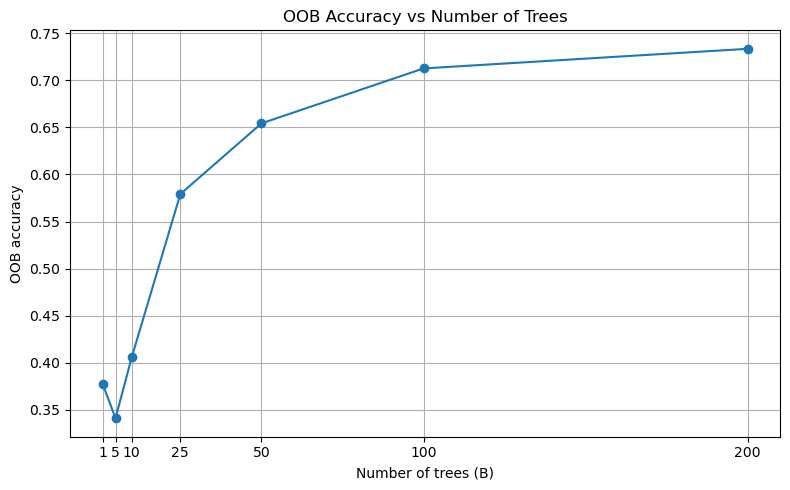

In [65]:
plt.figure(figsize=(8, 5))
plt.plot(q1c_df["B"], q1c_df["oob_accuracy"], marker="o")
plt.xticks(B_values)
plt.xlabel("Number of trees (B)")
plt.ylabel("OOB accuracy")
plt.title("OOB Accuracy vs Number of Trees")
plt.grid(True)
plt.tight_layout()
plt.show()


### Average pairwise disagreement versus ensemble size

For each value of B, disagreement is averaged over every pair of trees, using their predictions on the validation images. The value for B = 1 is undefined because there is no tree pair.

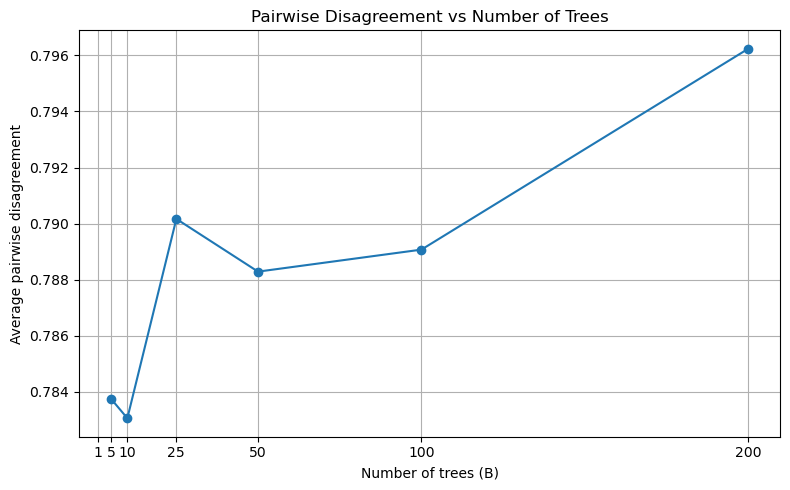

In [66]:
plt.figure(figsize=(8, 5))
plt.plot(q1c_df["B"], q1c_df["pairwise_disagreement"], marker="o")
plt.xticks(B_values)
plt.xlabel("Number of trees (B)")
plt.ylabel("Average pairwise disagreement")
plt.title("Pairwise Disagreement vs Number of Trees")
plt.grid(True)
plt.tight_layout()
plt.show()

### Mean vote margin versus ensemble size

For each validation image, the margin is the winning vote fraction minus the runner-up vote fraction. The plot shows the average margin across validation images.

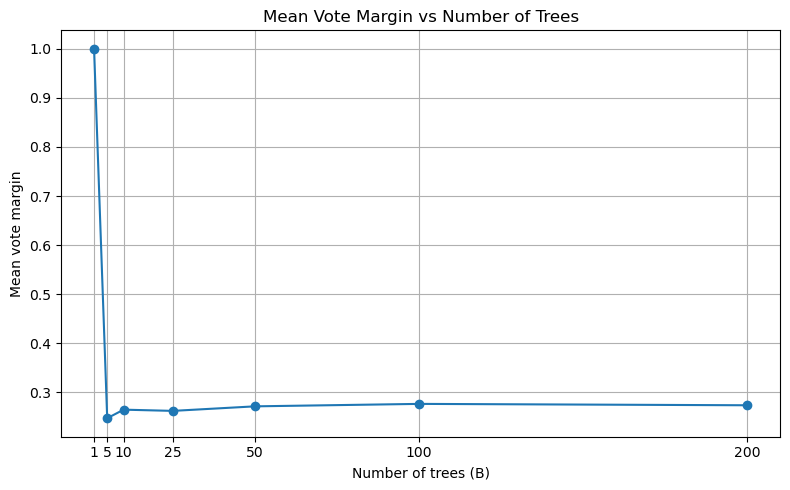

In [67]:
plt.figure(figsize=(8, 5))
plt.plot(q1c_df["B"], q1c_df["mean_vote_margin"], marker="o")
plt.xticks(B_values)
plt.xlabel("Number of trees (B)")
plt.ylabel("Mean vote margin")
plt.title("Mean Vote Margin vs Number of Trees")
plt.grid(True)
plt.tight_layout()
plt.show()

### Select and freeze the final ensemble size using validation accuracy

The final ensemble size is selected **only using validation accuracy**. If multiple values of \(B\) have exactly the same maximum validation accuracy, `idxmax()` selects the first one in the ascending `B_values` order (the smaller ensemble). Test accuracy is not used for selection.

In [68]:
best_q1c_idx = q1c_df["validation_accuracy"].idxmax()
final_B = int(q1c_df.loc[best_q1c_idx, "B"])

final_bagged_trees = bagged_trees[:final_B]

print("Selected final ensemble size (B):", final_B)
print("Best validation accuracy:",
      q1c_df.loc[best_q1c_idx, "validation_accuracy"])
print("Number of trees in final ensemble:", len(final_bagged_trees))

Selected final ensemble size (B): 100
Best validation accuracy: 0.875
Number of trees in final ensemble: 100


## Q1(d). Clean and masked test-set comparison

This section compares the frozen single decision tree from Q1(a) with the final bagged ensemble selected using validation accuracy in Q1(c). Both models are evaluated on the original clean test images and on a masked copy of those images. The models are not retrained for the masked experiment.

### Create the masked test set

Each 64 × 64 test image is reshaped to its original dimensions. The centred block covering rows 24–39 and columns 24–39 is set to zero, and the result is flattened again to 4096 raw pixel values. The original clean test set remains unchanged.

In [69]:
x_test_images = x_test.reshape(-1, 64, 64).copy()
x_test_masked_images = x_test_images.copy()
x_test_masked_images[:, 24:40, 24:40] = 0.0
x_test_masked = x_test_masked_images.reshape(len(x_test), -1)

print("Clean test set shape:", x_test.shape)
print("Masked test set shape:", x_test_masked.shape)
print("Masked block shape:", x_test_masked_images[:, 24:40, 24:40].shape)

Clean test set shape: (80, 4096)
Masked test set shape: (80, 4096)
Masked block shape: (80, 16, 16)


### Accuracy and prediction confidence

The single-tree confidence is the largest class probability returned by `predict_proba` for each image. The bagging confidence is the fraction of trees voting for the ensemble’s winning identity. Mean confidence is averaged over all test images. These are model-specific confidence measures and should not be interpreted as perfectly calibrated probabilities.

In [70]:
classes_d = np.unique(y_train)

def predict_with_bagging_votes(X_eval, trees, class_labels):
    votes = np.zeros((len(X_eval), len(class_labels)), dtype=int)
    for tree in trees:
        predictions = tree.predict(X_eval)
        columns = np.searchsorted(class_labels, predictions)
        votes[np.arange(len(X_eval)), columns] += 1
    predicted_labels = class_labels[np.argmax(votes, axis=1)]
    confidence = np.max(votes, axis=1) / len(trees)
    return predicted_labels, confidence, votes

test_sets_d = {
    "Clean": x_test,
    "Masked": x_test_masked
}

q1d_predictions = {}
q1d_summary = []

for set_name, X_eval in test_sets_d.items():
    tree_predictions = best_tree.predict(X_eval)
    tree_probabilities = best_tree.predict_proba(X_eval)
    tree_confidence = np.max(tree_probabilities, axis=1)

    bagging_predictions, bagging_confidence, bagging_votes = predict_with_bagging_votes(
        X_eval, final_bagged_trees, classes_d
    )

    q1d_predictions[set_name] = {
        "tree_predictions": tree_predictions,
        "tree_confidence": tree_confidence,
        "bagging_predictions": bagging_predictions,
        "bagging_confidence": bagging_confidence,
        "bagging_votes": bagging_votes
    }

    q1d_summary.append({
        "Test set": set_name,
        "Model": "Single tree",
        "Accuracy": accuracy_score(y_test, tree_predictions),
        "Mean prediction confidence": np.mean(tree_confidence)
    })
    q1d_summary.append({
        "Test set": set_name,
        "Model": "Bagging",
        "Accuracy": accuracy_score(y_test, bagging_predictions),
        "Mean prediction confidence": np.mean(bagging_confidence)
    })

q1d_summary_df = pd.DataFrame(q1d_summary)
print(q1d_summary_df.round(4).to_string(index=False))

Test set       Model  Accuracy  Mean prediction confidence
   Clean Single tree    0.5000                      0.9765
   Clean     Bagging    0.8500                      0.3790
  Masked Single tree    0.5000                      0.9765
  Masked     Bagging    0.7375                      0.2692


                 Case Test set  Test position  Original image index  True identity  Tree prediction  Tree confidence  Bagging prediction  Bagging confidence                                                                                                                                                                                       Bagging vote counts
Bagging corrects tree   Masked              1                     4              0               29         1.000000                   0                0.21                  {0: 21, 1: 14, 13: 6, 17: 6, 30: 5, 33: 5, 35: 5, 3: 4, 4: 4, 9: 4, 15: 4, 26: 3, 8: 2, 16: 2, 22: 2, 36: 2, 5: 1, 11: 1, 12: 1, 14: 1, 19: 1, 20: 1, 25: 1, 27: 1, 29: 1, 37: 1, 38: 1}
Bagging corrects tree   Masked              5                    27              2                4         0.857143                   2                0.19                                             {2: 19, 30: 12, 27: 8, 33: 8, 3: 7, 12: 7, 35: 7, 13: 6, 14: 4, 1: 3, 20: 3, 25: 

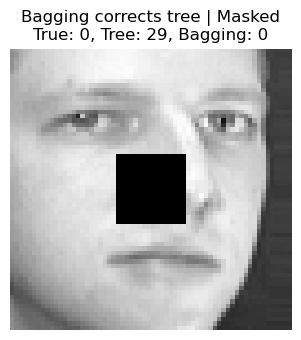

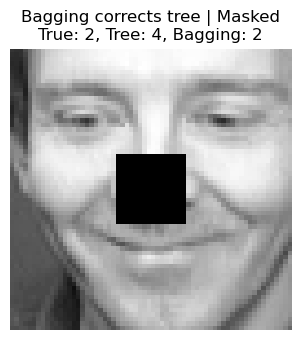

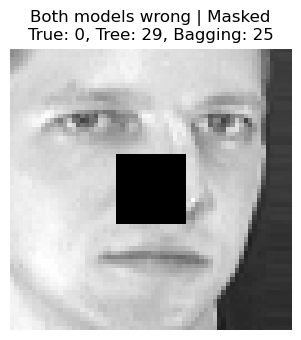

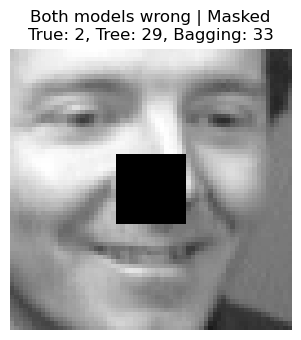

In [71]:
example_records = []
used_test_indices = set()

case_conditions = [
    ("Bagging corrects tree", lambda tree_p, bag_p, true_y: (tree_p != true_y) & (bag_p == true_y)),
    ("Both models wrong", lambda tree_p, bag_p, true_y: (tree_p != true_y) & (bag_p != true_y))
]

for case_name, condition in case_conditions:
    selected_count = 0
    for set_name in ["Masked", "Clean"]:
        outputs = q1d_predictions[set_name]
        tree_predictions = outputs["tree_predictions"]
        bagging_predictions = outputs["bagging_predictions"]
        matches = np.where(condition(tree_predictions, bagging_predictions, y_test))[0]

        for test_position in matches:
            original_index = int(test_idx[test_position])
            if original_index in used_test_indices:
                continue

            votes_for_image = outputs["bagging_votes"][test_position]
            vote_counts = {
                int(class_labels): int(vote_count)
                for class_labels, vote_count in zip(classes_d, votes_for_image)
                if vote_count > 0
            }
            ordered_vote_counts = dict(sorted(
                vote_counts.items(), key=lambda item: (-item[1], item[0])
            ))

            example_records.append({
                "Case": case_name,
                "Test set": set_name,
                "Test position": int(test_position),
                "Original image index": original_index,
                "True identity": int(y_test[test_position]),
                "Tree prediction": int(tree_predictions[test_position]),
                "Tree confidence": float(outputs["tree_confidence"][test_position]),
                "Bagging prediction": int(bagging_predictions[test_position]),
                "Bagging confidence": float(outputs["bagging_confidence"][test_position]),
                "Bagging vote counts": ordered_vote_counts
            })
            used_test_indices.add(original_index)
            selected_count += 1
            if selected_count == 2:
                break
        if selected_count == 2:
            break

q1d_examples_df = pd.DataFrame(example_records)
if len(q1d_examples_df) > 0:
    print(q1d_examples_df.to_string(index=False))
else:
    print("No qualifying examples were found.")

for example_number, example in enumerate(example_records, start=1):
    image_position = example["Test position"]
    if example["Test set"] == "Masked":
        face_image = x_test_masked_images[image_position]
    else:
        face_image = x_test_images[image_position]

    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(face_image, cmap="gray")
    plt.title(
        f"{example['Case']} | {example['Test set']}\n"
        f"True: {example['True identity']}, "
        f"Tree: {example['Tree prediction']}, "
        f"Bagging: {example['Bagging prediction']}"
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Interpretation: errors reduced and errors that remain

Bagging can reduce errors caused by the instability or high variance of an individual decision tree. Different bootstrap samples produce different trees, and majority voting can cancel some sample-specific mistakes when the trees do not all make the same error. This is the type of error illustrated by cases where the single tree is wrong but the bagged ensemble is correct.

Bagging cannot reliably remove systematic errors shared by many or all base trees. For example, if the masked region removes useful facial information, if two identities are difficult to distinguish from the remaining pixels, or if the raw-pixel representation creates a shared bias, many trees may vote for the same incorrect identity. Majority voting can reinforce such an error rather than fix it. A high vote confidence therefore indicates agreement, not a guarantee that the prediction is correct.

Use the measured clean-versus-masked accuracy and confidence table, together with the four selected examples, to state how strongly masking affects this particular experiment.

## Q2(a).

In [72]:
samme_X = np.arange(9, dtype=float).reshape(-1, 1)
samme_y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
samme_sample_ids = np.arange(1, len(samme_y) + 1)
samme_classes = np.unique(samme_y)
samme_K = len(samme_classes)
samme_n = len(samme_y)
samme_initial_weights = np.full(samme_n, 1.0 / samme_n)

In [73]:
samme_weak_learner = DecisionTreeClassifier(max_depth=1, random_state=SEED)
samme_weak_learner.fit(
    samme_X,
    samme_y,
    sample_weight=samme_initial_weights
)
samme_predictions = samme_weak_learner.predict(samme_X)
samme_incorrect = (samme_predictions != samme_y)
samme_weighted_error = float(np.sum(samme_initial_weights * samme_incorrect))
samme_random_error_threshold = 1.0 - 1.0 / samme_K

In [74]:
print("Number of samples:", samme_n)
print("Number of classes (K):", samme_K)
print("Class labels:", samme_classes)
print("Random-guessing error threshold:", samme_random_error_threshold)
print("Initial sample weights:", samme_initial_weights)
print("Weak learner predictions:", samme_predictions)
print("Weighted error:", samme_weighted_error)

Number of samples: 9
Number of classes (K): 3
Class labels: [0 1 2]
Random-guessing error threshold: 0.6666666666666667
Initial sample weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Weak learner predictions: [0 0 0 1 1 1 1 1 1]
Weighted error: 0.3333333333333333


In [75]:
if samme_weighted_error >= samme_random_error_threshold:
    samme_alpha = None
    samme_normalizer = None
    samme_updated_weights = samme_initial_weights.copy()
    print("Weak learner rejected: its weighted error is not better than random multiclass prediction.")
elif np.isclose(samme_weighted_error, 0.0):
    samme_alpha = np.inf
    samme_normalizer = None
    samme_updated_weights = samme_initial_weights.copy()
    print("Perfect weak learner: stop boosting immediately; no finite alpha or weight update is needed.")
else:
    samme_alpha = (
        np.log((1.0 - samme_weighted_error) / samme_weighted_error)
        + np.log(samme_K - 1)
    )
    samme_unnormalized_weights = (
        samme_initial_weights * np.exp(samme_alpha * samme_incorrect)
    )
    samme_normalizer = float(np.sum(samme_unnormalized_weights))
    samme_updated_weights = samme_unnormalized_weights / samme_normalizer
    print("SAMME learner weight (alpha):", samme_alpha)
    print("Weight normalization constant:", samme_normalizer)
    print("Updated sample weights:", samme_updated_weights)

SAMME learner weight (alpha): 1.3862943611198908
Weight normalization constant: 2.0
Updated sample weights: [0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]


In [76]:
samme_round_log = pd.DataFrame({
    "sample": samme_sample_ids,
    "feature": samme_X[:, 0],
    "true_class": samme_y,
    "initial_weight": samme_initial_weights,
    "weak_prediction": samme_predictions,
    "correct": ~samme_incorrect,
    "updated_weight": samme_updated_weights
})
print("\nComplete SAMME round log:")
display(samme_round_log)


Complete SAMME round log:


,sample,feature,true_class,initial_weight,weak_prediction,correct,updated_weight
0,1,0.0,0,0.111111,0,True,0.055556
1,2,1.0,0,0.111111,0,True,0.055556
2,3,2.0,0,0.111111,0,True,0.055556
3,4,3.0,1,0.111111,1,True,0.055556
4,5,4.0,1,0.111111,1,True,0.055556
5,6,5.0,1,0.111111,1,True,0.055556
6,7,6.0,2,0.111111,1,False,0.222222
7,8,7.0,2,0.111111,1,False,0.222222
8,9,8.0,2,0.111111,1,False,0.222222


In [77]:
if samme_alpha is not None and np.isfinite(samme_alpha):
    print("Sum of updated weights:", np.sum(samme_updated_weights))
    print("Total updated weight on correctly classified samples:",
          np.sum(samme_updated_weights[~samme_incorrect]))
    print("Total updated weight on incorrectly classified samples:",
          np.sum(samme_updated_weights[samme_incorrect]))

Sum of updated weights: 1.0
Total updated weight on correctly classified samples: 0.33333333333333337
Total updated weight on incorrectly classified samples: 0.6666666666666667


## Q2(b).

The next experiment trains SAMME multiclass boosting models on the clean Olivetti training images. Each weak learner is a decision tree with one of the specified maximum depths. The sample weights are updated using the SAMME rule from Q2(a). Validation accuracy on the clean validation set is used to select the depth and number of rounds.

For Q2(c), the training time of each accepted weak learner and the training-face prediction and weight histories are retained.

In [78]:
samme_face_depths = [1, 2, 3, 4]
samme_face_rounds = [10, 25, 50, 100]
samme_face_max_rounds = max(samme_face_rounds)
samme_face_classes = np.unique(y_train)
samme_face_K = len(samme_face_classes)
samme_face_n = len(y_train)
samme_face_threshold = 1 - 1 / samme_face_K

In [79]:
print("Training images:", samme_face_n)
print("Number of classes:", samme_face_K)
print("Random-guessing error threshold:", samme_face_threshold)
print("Tree depths:", samme_face_depths)
print("Round counts:", samme_face_rounds)

Training images: 240
Number of classes: 40
Random-guessing error threshold: 0.975
Tree depths: [1, 2, 3, 4]
Round counts: [10, 25, 50, 100]


In [80]:
samme_face_models = {}

In [81]:
for depth in samme_face_depths:
    weights = np.ones(samme_face_n) / samme_face_n
    learners = []
    learner_weights = []
    fit_times = []
    train_prediction_history = []
    sample_weight_history = [weights.copy()]
    history = []
    perfect_learner = None
    perfect_round = None
    stop_reason = "Reached the requested maximum number of rounds"

    for round_number in range(1, samme_face_max_rounds + 1):
        weak_learner = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + depth * 1000 + round_number
        )
        start_time = time.perf_counter()
        weak_learner.fit(x_train, y_train, sample_weight=weights)
        round_fit_time = time.perf_counter() - start_time
        train_predictions = weak_learner.predict(x_train)
        incorrect = train_predictions != y_train
        weighted_error = np.sum(weights * incorrect)

        if weighted_error >= samme_face_threshold:
            history.append({
                "round": round_number,
                "weighted_training_error": weighted_error,
                "learner_weight": np.nan,
                "maximum_sample_weight": np.max(weights),
                "top10_weight_sum": np.sum(np.sort(weights)[-10:]),
                "accepted": False
            })
            stop_reason = "Stopped: weak learner was not better than random"
            break

        if np.isclose(weighted_error, 0.0):
            learners.append(weak_learner)
            learner_weights.append(np.nan)
            fit_times.append(round_fit_time)
            train_prediction_history.append(train_predictions.copy())
            sample_weight_history.append(weights.copy())
            perfect_learner = weak_learner
            perfect_round = round_number
            history.append({
                "round": round_number,
                "weighted_training_error": weighted_error,
                "learner_weight": np.nan,
                "maximum_sample_weight": np.max(weights),
                "top10_weight_sum": np.sum(np.sort(weights)[-10:]),
                "accepted": True
            })
            stop_reason = "Stopped: perfect weak learner"
            break

        alpha = np.log((1 - weighted_error) / weighted_error) + np.log(samme_face_K - 1)
        weights = weights * np.exp(alpha * incorrect)
        weights = weights / np.sum(weights)

        learners.append(weak_learner)
        learner_weights.append(alpha)
        fit_times.append(round_fit_time)
        train_prediction_history.append(train_predictions.copy())
        sample_weight_history.append(weights.copy())
        history.append({
            "round": round_number,
            "weighted_training_error": weighted_error,
            "learner_weight": alpha,
            "maximum_sample_weight": np.max(weights),
            "top10_weight_sum": np.sum(np.sort(weights)[-10:]),
            "accepted": True
        })

    samme_face_models[depth] = {
        "learners": learners,
        "alphas": learner_weights,
        "fit_times": fit_times,
        "sample_weight_history": sample_weight_history,
        "train_prediction_history": train_prediction_history,
        "history": pd.DataFrame(history),
        "perfect_learner": perfect_learner,
        "perfect_round": perfect_round,
        "stop_reason": stop_reason
    }

In [82]:
samme_training_summary = []

In [83]:
for depth in samme_face_depths:
    model = samme_face_models[depth]
    samme_training_summary.append({
        "depth": depth,
        "accepted_rounds": len(model["learners"]),
        "stop_reason": model["stop_reason"]
    })

In [84]:
samme_training_summary_df = pd.DataFrame(samme_training_summary)
display(samme_training_summary_df)

,depth,accepted_rounds,stop_reason
0,1,100,Reached the requested maximum number of rounds
1,2,100,Reached the requested maximum number of rounds
2,3,100,Reached the requested maximum number of rounds
3,4,100,Reached the requested maximum number of rounds


In [85]:
def samme_face_predict(model, X_eval, requested_rounds):
    used_rounds = min(requested_rounds, len(model["learners"]))

    if used_rounds == 0:
        return None

    if model["perfect_round"] is not None and model["perfect_round"] <= requested_rounds:
        return model["perfect_learner"].predict(X_eval)

    scores = np.zeros((len(X_eval), samme_face_K))

    for learner, alpha in zip(
        model["learners"][:used_rounds],
        model["alphas"][:used_rounds]
    ):
        predictions = learner.predict(X_eval)
        columns = np.searchsorted(samme_face_classes, predictions)
        scores[np.arange(len(X_eval)), columns] += alpha

    return samme_face_classes[np.argmax(scores, axis=1)]

In [86]:
samme_validation_results = []

In [87]:
for depth in samme_face_depths:
    model = samme_face_models[depth]

    for requested_rounds in samme_face_rounds:
        predictions = samme_face_predict(model, x_val, requested_rounds)

        if predictions is None:
            validation_accuracy = np.nan
        else:
            validation_accuracy = accuracy_score(y_val, predictions)

        samme_validation_results.append({
            "depth": depth,
            "requested_rounds": requested_rounds,
            "accepted_rounds": min(requested_rounds, len(model["learners"])),
            "validation_accuracy": validation_accuracy
        })

In [88]:
samme_validation_df = pd.DataFrame(samme_validation_results)
display(samme_validation_df)

,depth,requested_rounds,accepted_rounds,validation_accuracy
0,1,10,10,0.0250
1,1,25,25,0.0500
2,1,50,50,0.1000
3,1,100,100,0.1625
4,2,10,10,0.0375
5,2,25,25,0.0375
6,2,50,50,0.0250
7,2,100,100,0.1000
8,3,10,10,0.2000
9,3,25,25,0.1375


In [89]:
valid_results = samme_validation_df.dropna(subset=["validation_accuracy"])
best_samme_index = valid_results["validation_accuracy"].idxmax()
best_samme_row = samme_validation_df.loc[best_samme_index]

In [90]:
best_samme_depth = int(best_samme_row["depth"])
best_samme_rounds = int(best_samme_row["requested_rounds"])
best_samme_model = samme_face_models[best_samme_depth]

In [91]:
print("Selected weak learner depth:", best_samme_depth)
print("Selected number of rounds:", best_samme_rounds)
print("Accepted rounds:", min(best_samme_rounds, len(best_samme_model["learners"])))
print("Clean validation accuracy:", best_samme_row["validation_accuracy"])

Selected weak learner depth: 4
Selected number of rounds: 100
Accepted rounds: 100
Clean validation accuracy: 0.4125


In [92]:
samme_selected_history = best_samme_model["history"]
samme_selected_history = samme_selected_history[
    (samme_selected_history["accepted"] == True)
    & (samme_selected_history["round"] <= best_samme_rounds)
].copy()

print("Selected model history:")
display(samme_selected_history)

Selected model history:


,round,weighted_training_error,learner_weight,maximum_sample_weight,top10_weight_sum,accepted
0,1,0.875000,1.717651,0.004643,0.046429,True
1,2,0.860714,1.842326,0.005259,0.052593,True
2,3,0.841387,1.994980,0.006095,0.060945,True
3,4,0.777744,2.410993,0.007640,0.076403,True
4,5,0.752307,2.552606,0.009902,0.099019,True
...,...,...,...,...,...,...
95,96,0.670564,2.952825,0.073019,0.382478,True
96,97,0.652819,3.032109,0.075615,0.381709,True
97,98,0.681295,2.903831,0.050682,0.289205,True
98,99,0.613197,3.202789,0.046395,0.239812,True


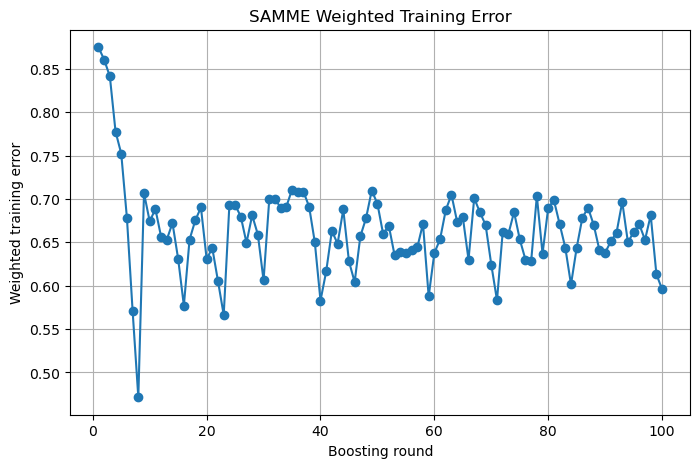

In [93]:
plt.figure(figsize=(8, 5))
plt.plot(
    samme_selected_history["round"],
    samme_selected_history["weighted_training_error"],
    marker="o"
)
plt.xlabel("Boosting round")
plt.ylabel("Weighted training error")
plt.title("SAMME Weighted Training Error")
plt.grid(True)
plt.show()

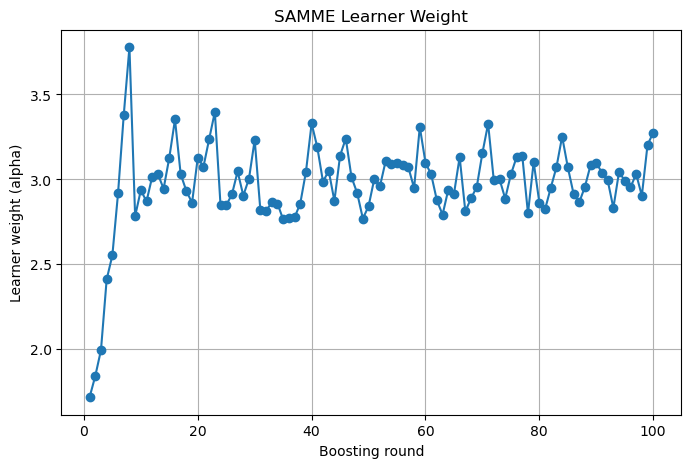

In [94]:
plt.figure(figsize=(8, 5))
plt.plot(
    samme_selected_history["round"],
    samme_selected_history["learner_weight"],
    marker="o"
)
plt.xlabel("Boosting round")
plt.ylabel("Learner weight (alpha)")
plt.title("SAMME Learner Weight")
plt.grid(True)
plt.show()

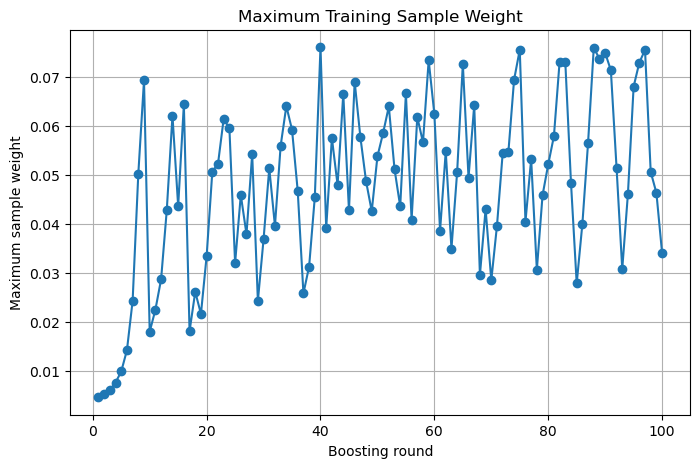

In [95]:
plt.figure(figsize=(8, 5))
plt.plot(
    samme_selected_history["round"],
    samme_selected_history["maximum_sample_weight"],
    marker="o"
)
plt.xlabel("Boosting round")
plt.ylabel("Maximum sample weight")
plt.title("Maximum Training Sample Weight")
plt.grid(True)
plt.show()

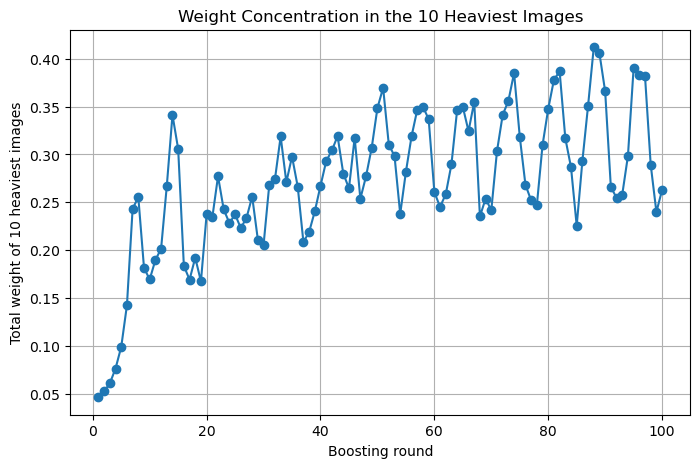

In [96]:
plt.figure(figsize=(8, 5))
plt.plot(
    samme_selected_history["round"],
    samme_selected_history["top10_weight_sum"],
    marker="o"
)
plt.xlabel("Boosting round")
plt.ylabel("Total weight of 10 heaviest images")
plt.title("Weight Concentration in the 10 Heaviest Images")
plt.grid(True)
plt.show()

## Q2(c).

Compare the selected SAMME boosting model with bagging at 25, 50 and 100 learners. Report training, clean-validation and clean-test accuracy, together with cumulative weak-learner fitting time. The fit-time totals use the time recorded around each individual model's `fit` call, so prediction and plotting time are excluded.

The final section identifies a training image that receives a large boosting weight. Its weak-learner predictions and sample weights are shown round by round to explain how SAMME redirects attention to repeatedly misclassified examples.

In [97]:
comparison_sizes = [25, 50, 100]
comparison_classes = np.unique(y_train)
comparison_results = []

In [98]:
print("Selected boosting depth:", best_samme_depth)
print("Selected boosting rounds in Q2(b):", best_samme_rounds)
print("Accepted boosting learners at selected depth:", len(best_samme_model["learners"]))
print("Available bagging trees:", len(bagged_trees))

Selected boosting depth: 4
Selected boosting rounds in Q2(b): 100
Accepted boosting learners at selected depth: 100
Available bagging trees: 200


In [99]:
for n_learners in comparison_sizes:
    trees = bagged_trees[:n_learners]
    votes_train = np.zeros((len(x_train), len(comparison_classes)), dtype=int)
    votes_val = np.zeros((len(x_val), len(comparison_classes)), dtype=int)
    votes_test = np.zeros((len(x_test), len(comparison_classes)), dtype=int)

    for tree in trees:
        pred_train = tree.predict(x_train)
        pred_val = tree.predict(x_val)
        pred_test = tree.predict(x_test)

        col_train = np.searchsorted(comparison_classes, pred_train)
        col_val = np.searchsorted(comparison_classes, pred_val)
        col_test = np.searchsorted(comparison_classes, pred_test)

        votes_train[np.arange(len(x_train)), col_train] += 1
        votes_val[np.arange(len(x_val)), col_val] += 1
        votes_test[np.arange(len(x_test)), col_test] += 1

    pred_train = comparison_classes[np.argmax(votes_train, axis=1)]
    pred_val = comparison_classes[np.argmax(votes_val, axis=1)]
    pred_test = comparison_classes[np.argmax(votes_test, axis=1)]
    fit_time = np.sum(bagging_fit_times[:n_learners])

    comparison_results.append({
        "Learners": n_learners,
        "Model": "Bagging",
        "Weak learner depth": best_depth,
        "Used learners": len(trees),
        "Train accuracy": accuracy_score(y_train, pred_train),
        "Validation accuracy": accuracy_score(y_val, pred_val),
        "Clean test accuracy": accuracy_score(y_test, pred_test),
        "Training time (seconds)": fit_time
    })

In [100]:
for n_learners in comparison_sizes:
    used_learners = min(n_learners, len(best_samme_model["learners"]))
    pred_train = samme_face_predict(best_samme_model, x_train, n_learners)
    pred_val = samme_face_predict(best_samme_model, x_val, n_learners)
    pred_test = samme_face_predict(best_samme_model, x_test, n_learners)

    if pred_train is None:
        train_accuracy = np.nan
        val_accuracy = np.nan
        test_accuracy = np.nan
    else:
        train_accuracy = accuracy_score(y_train, pred_train)
        val_accuracy = accuracy_score(y_val, pred_val)
        test_accuracy = accuracy_score(y_test, pred_test)

    fit_time = np.sum(best_samme_model["fit_times"][:used_learners])

    comparison_results.append({
        "Learners": n_learners,
        "Model": "SAMME boosting",
        "Weak learner depth": best_samme_depth,
        "Used learners": used_learners,
        "Train accuracy": train_accuracy,
        "Validation accuracy": val_accuracy,
        "Clean test accuracy": test_accuracy,
        "Training time (seconds)": fit_time
    })

In [101]:
comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(["Learners", "Model"]).reset_index(drop=True)
display(comparison_df.round(4))

,Learners,Model,Weak learner depth,Used learners,Train accuracy,Validation accuracy,Clean test accuracy,Training time (seconds)
0,25,Bagging,NaN,25,1.0000,0.8250,0.7875,16.4057
1,25,SAMME boosting,4.0,25,0.8000,0.2875,0.2875,4.8291
2,50,Bagging,NaN,50,1.0000,0.8250,0.8125,32.7854
3,50,SAMME boosting,4.0,50,0.9000,0.3875,0.2375,9.7306
4,100,Bagging,NaN,100,1.0000,0.8750,0.8500,64.7636
5,100,SAMME boosting,4.0,100,0.9875,0.4125,0.4000,19.8090


In [102]:
n_history_rounds = min(best_samme_rounds, len(best_samme_model["learners"]))
weight_history = np.asarray(
    best_samme_model["sample_weight_history"][:n_history_rounds + 1]
)
prediction_history = best_samme_model["train_prediction_history"][:n_history_rounds]

Training position: 176
Original dataset image index: 292
True identity: 29
Peak sample weight: 0.076162
Round when peak weight was reached: 40


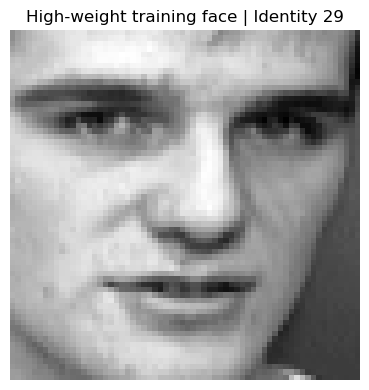

Prediction and weight history for the selected face:


,Round,True identity,Weak learner prediction,Correct,Weight before round,Weight after round
0,1,29,0,False,0.004167,0.004643
1,2,29,1,False,0.004643,0.005259
2,3,29,2,False,0.005259,0.006095
3,4,29,3,False,0.006095,0.007640
4,5,29,29,True,0.007640,0.000771
...,...,...,...,...,...,...
95,96,29,2,False,0.009389,0.013652
96,97,29,4,False,0.013652,0.020389
97,98,29,30,False,0.020389,0.029179
98,99,29,8,False,0.029179,0.046395


In [103]:
if len(weight_history) <= 1 or len(prediction_history) == 0:
    print("The selected boosting model has no accepted rounds to inspect.")
else:
    post_update_weights = weight_history[1:]
    sample_position = int(np.argmax(np.max(post_update_weights, axis=0)))
    peak_round = int(np.argmax(post_update_weights[:, sample_position]) + 1)
    peak_weight = post_update_weights[peak_round - 1, sample_position]
    original_image_index = int(train_idx[sample_position])
    true_identity = int(y_train[sample_position])

    print("Training position:", sample_position)
    print("Original dataset image index:", original_image_index)
    print("True identity:", true_identity)
    print("Peak sample weight:", round(float(peak_weight), 6))
    print("Round when peak weight was reached:", peak_round)

    plt.figure(figsize=(4, 4))
    plt.imshow(images[original_image_index], cmap="gray")
    plt.title(f"High-weight training face | Identity {true_identity}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    prediction_rows = []
    for round_index, round_predictions in enumerate(prediction_history, start=1):
        round_prediction = int(round_predictions[sample_position])
        prediction_rows.append({
            "Round": round_index,
            "True identity": true_identity,
            "Weak learner prediction": round_prediction,
            "Correct": round_prediction == true_identity,
            "Weight before round": weight_history[round_index - 1, sample_position],
            "Weight after round": weight_history[round_index, sample_position]
        })

    print("Prediction and weight history for the selected face:")
    display(pd.DataFrame(prediction_rows).round(6))

## Q2(d).

In [104]:
final_samme_depth = best_samme_depth
final_samme_rounds = best_samme_rounds
final_samme_model = best_samme_model

print("Frozen SAMME depth:", final_samme_depth)
print("Frozen SAMME requested rounds:", final_samme_rounds)
print("Accepted SAMME learners:", len(final_samme_model["learners"]))
print("Final bagging learners:", len(final_bagged_trees))

Frozen SAMME depth: 4
Frozen SAMME requested rounds: 100
Accepted SAMME learners: 100
Final bagging learners: 100


In [105]:
x_test_clean_q2d = x_test.copy()
x_test_masked_images_q2d = x_test.reshape(-1, 64, 64).copy()
x_test_masked_images_q2d[:, 24:40, 24:40] = 0.0
x_test_masked_q2d = x_test_masked_images_q2d.reshape(len(x_test), -1)

In [106]:
print("Frozen SAMME depth:", final_samme_depth)
print("Frozen SAMME requested rounds:", final_samme_rounds)
print("Accepted SAMME learners:", len(final_samme_model["learners"]))
print("Final bagging learners:", len(final_bagged_trees))

Frozen SAMME depth: 4
Frozen SAMME requested rounds: 100
Accepted SAMME learners: 100
Final bagging learners: 100


In [107]:
def samme_face_predict_with_confidence(model, X_eval, requested_rounds):
    used_rounds = min(requested_rounds, len(model["learners"]))

    if used_rounds == 0:
        return None, None, None

    if model["perfect_round"] is not None and model["perfect_round"] <= requested_rounds:
        predicted = model["perfect_learner"].predict(X_eval)
        q = np.zeros((len(X_eval), len(samme_face_classes)))
        columns = np.searchsorted(samme_face_classes, predicted)
        q[np.arange(len(X_eval)), columns] = 1.0
        return predicted, q, np.max(q, axis=1)

    scores = np.zeros((len(X_eval), len(samme_face_classes)))
    total_alpha = 0.0

    for learner, alpha in zip(
        model["learners"][:used_rounds],
        model["alphas"][:used_rounds]
    ):
        if not np.isfinite(alpha):
            continue
        learner_predictions = learner.predict(X_eval)
        columns = np.searchsorted(samme_face_classes, learner_predictions)
        scores[np.arange(len(X_eval)), columns] += alpha
        total_alpha += alpha

    if total_alpha <= 0:
        return None, None, None

    q = scores / total_alpha
    predicted = samme_face_classes[np.argmax(q, axis=1)]
    confidence = np.max(q, axis=1)
    return predicted, q, confidence

In [108]:
q2d_test_sets = {
    "Clean": x_test_clean_q2d,
    "Masked": x_test_masked_q2d
}

In [109]:
q2d_predictions = {}
q2d_results = []
q2d_classes = np.unique(y_train)

In [110]:
for set_name, X_eval in q2d_test_sets.items():
    tree_pred = best_tree.predict(X_eval)
    tree_prob = best_tree.predict_proba(X_eval)
    tree_conf = np.max(tree_prob, axis=1)

    bag_pred, bag_conf, bag_votes = predict_with_bagging_votes(
        X_eval, final_bagged_trees, q2d_classes
    )

    boost_pred, boost_q, boost_conf = samme_face_predict_with_confidence(
        final_samme_model, X_eval, final_samme_rounds
    )

    q2d_predictions[set_name] = {
        "tree_pred": tree_pred,
        "tree_conf": tree_conf,
        "bag_pred": bag_pred,
        "bag_conf": bag_conf,
        "bag_votes": bag_votes,
        "boost_pred": boost_pred,
        "boost_q": boost_q,
        "boost_conf": boost_conf
    }

    q2d_results.extend([
        {
            "Test set": set_name,
            "Model": "Single tree",
            "Accuracy": accuracy_score(y_test, tree_pred),
            "Mean winning probability/vote": np.mean(tree_conf)
        },
        {
            "Test set": set_name,
            "Model": "Bagging",
            "Accuracy": accuracy_score(y_test, bag_pred),
            "Mean winning probability/vote": np.mean(bag_conf)
        },
        {
            "Test set": set_name,
            "Model": "SAMME boosting",
            "Accuracy": accuracy_score(y_test, boost_pred),
            "Mean winning probability/vote": np.mean(boost_conf)
        }
    ])

In [111]:
q2d_results_df = pd.DataFrame(q2d_results)
display(q2d_results_df.round(4))

,Test set,Model,Accuracy,Mean winning probability/vote
0,Clean,Single tree,0.5000,0.9765
1,Clean,Bagging,0.8500,0.3790
2,Clean,SAMME boosting,0.4000,0.1205
3,Masked,Single tree,0.5000,0.9765
4,Masked,Bagging,0.7375,0.2692
5,Masked,SAMME boosting,0.4500,0.1163


In [112]:
clean_out = q2d_predictions["Clean"]
masked_out = q2d_predictions["Masked"]

bag_changed = clean_out["bag_pred"] != masked_out["bag_pred"]
boost_changed = clean_out["boost_pred"] != masked_out["boost_pred"]
bag_masked_correct = masked_out["bag_pred"] == y_test
boost_masked_correct = masked_out["boost_pred"] == y_test
both_clean_correct = (
    (clean_out["bag_pred"] == y_test)
    & (clean_out["boost_pred"] == y_test)
)

In [113]:
candidate_scores = []
for position in range(len(y_test)):
    response_differs = (
        bag_changed[position] != boost_changed[position]
        or masked_out["bag_pred"][position] != masked_out["boost_pred"][position]
        or bag_masked_correct[position] != boost_masked_correct[position]
    )
    if response_differs:
        score = (
            int(both_clean_correct[position]),
            int(bag_masked_correct[position] != boost_masked_correct[position]),
            int(bag_changed[position] != boost_changed[position]),
            int(masked_out["bag_pred"][position] != masked_out["boost_pred"][position]),
            abs(float(clean_out["bag_conf"][position] - masked_out["bag_conf"][position]))
            + abs(float(clean_out["boost_conf"][position] - masked_out["boost_conf"][position]))
        )
        candidate_scores.append((score, position))

In [114]:
if candidate_scores:
    selected_test_position = max(candidate_scores, key=lambda item: item[0])[1]
else:
    bag_conf_change = np.abs(clean_out["bag_conf"] - masked_out["bag_conf"])
    boost_conf_change = np.abs(clean_out["boost_conf"] - masked_out["boost_conf"])
    selected_test_position = int(np.argmax(np.abs(bag_conf_change - boost_conf_change)))
selected_original_index = int(test_idx[selected_test_position])
selected_true_class = int(y_test[selected_test_position])

In [115]:
print("Test position:", selected_test_position)
print("Original Olivetti image index:", selected_original_index)
print("True identity:", selected_true_class)
print("Bagging changed prediction after masking:", bool(bag_changed[selected_test_position]))
print("Boosting changed prediction after masking:", bool(boost_changed[selected_test_position]))

Test position: 8
Original Olivetti image index: 40
True identity: 4
Bagging changed prediction after masking: False
Boosting changed prediction after masking: True


In [116]:
one_clean = x_test_clean_q2d[selected_test_position:selected_test_position + 1]
one_masked = x_test_masked_q2d[selected_test_position:selected_test_position + 1]

bag_tree_clean = np.array([tree.predict(one_clean)[0] for tree in final_bagged_trees])
bag_tree_masked = np.array([tree.predict(one_masked)[0] for tree in final_bagged_trees])

bag_classes_one = np.unique(np.concatenate([bag_tree_clean, bag_tree_masked]))
bag_counts_clean = {
    int(label): int(np.sum(bag_tree_clean == label)) for label in bag_classes_one
}
bag_counts_masked = {
    int(label): int(np.sum(bag_tree_masked == label)) for label in bag_classes_one
}


In [117]:
if len(bag_tree_clean) > 1:
    pairwise_disagreement_clean = np.mean([
        bag_tree_clean[i] != bag_tree_clean[j]
        for i in range(len(bag_tree_clean))
        for j in range(i + 1, len(bag_tree_clean))
    ])
    pairwise_disagreement_masked = np.mean([
        bag_tree_masked[i] != bag_tree_masked[j]
        for i in range(len(bag_tree_masked))
        for j in range(i + 1, len(bag_tree_masked))
    ])
else:
    pairwise_disagreement_clean = np.nan
    pairwise_disagreement_masked = np.nan

In [118]:
tree_flip_fraction = np.mean(bag_tree_clean != bag_tree_masked)

In [119]:
boost_used_rounds = min(final_samme_rounds, len(final_samme_model["learners"]))
boost_learners = final_samme_model["learners"][:boost_used_rounds]
boost_alphas = final_samme_model["alphas"][:boost_used_rounds]
boost_pred_clean_each = []
boost_pred_masked_each = []
boost_weighted_clean = {}
boost_weighted_masked = {}
boost_changed_weight = 0.0
boost_total_weight = 0.0

In [120]:
for learner, alpha in zip(boost_learners, boost_alphas):
    clean_label = int(learner.predict(one_clean)[0])
    masked_label = int(learner.predict(one_masked)[0])
    boost_pred_clean_each.append(clean_label)
    boost_pred_masked_each.append(masked_label)

    if np.isfinite(alpha):
        boost_total_weight += float(alpha)
        boost_weighted_clean[clean_label] = boost_weighted_clean.get(clean_label, 0.0) + float(alpha)
        boost_weighted_masked[masked_label] = boost_weighted_masked.get(masked_label, 0.0) + float(alpha)
        if clean_label != masked_label:
            boost_changed_weight += float(alpha)

In [121]:
boost_weighted_flip_fraction = (
    boost_changed_weight / boost_total_weight if boost_total_weight > 0 else np.nan
)


In [122]:
comparison_for_face = pd.DataFrame([
    {
        "Model": "Bagging",
        "Clean prediction": int(clean_out["bag_pred"][selected_test_position]),
        "Masked prediction": int(masked_out["bag_pred"][selected_test_position]),
        "Clean confidence": float(clean_out["bag_conf"][selected_test_position]),
        "Masked confidence": float(masked_out["bag_conf"][selected_test_position])
    },
    {
        "Model": "SAMME boosting",
        "Clean prediction": int(clean_out["boost_pred"][selected_test_position]),
        "Masked prediction": int(masked_out["boost_pred"][selected_test_position]),
        "Clean confidence": float(clean_out["boost_conf"][selected_test_position]),
        "Masked confidence": float(masked_out["boost_conf"][selected_test_position])
    }
])

In [123]:
display(comparison_for_face.round(4))
print("Bagging tree votes, clean:", bag_counts_clean)
print("Bagging tree votes, masked:", bag_counts_masked)
print("Bagging pairwise disagreement, clean:", round(float(pairwise_disagreement_clean), 4))
print("Bagging pairwise disagreement, masked:", round(float(pairwise_disagreement_masked), 4))
print("Fraction of bagging trees that changed prediction:", round(float(tree_flip_fraction), 4))
print("Boosting alpha-weighted votes, clean:", {k: round(v, 4) for k, v in boost_weighted_clean.items()})
print("Boosting alpha-weighted votes, masked:", {k: round(v, 4) for k, v in boost_weighted_masked.items()})
print("Fraction of finite boosting learner weight whose prediction changed:", round(float(boost_weighted_flip_fraction), 4))

,Model,Clean prediction,Masked prediction,Clean confidence,Masked confidence
0,Bagging,4,4,0.5000,0.2100
1,SAMME boosting,4,12,0.1185,0.1149


Bagging tree votes, clean: {1: 2, 2: 7, 3: 3, 4: 50, 5: 1, 6: 4, 8: 2, 9: 2, 11: 2, 12: 1, 13: 1, 14: 2, 17: 2, 20: 4, 21: 1, 22: 3, 23: 1, 26: 0, 30: 0, 33: 2, 34: 2, 35: 1, 37: 3, 38: 1, 39: 3}
Bagging tree votes, masked: {1: 2, 2: 6, 3: 6, 4: 21, 5: 0, 6: 2, 8: 0, 9: 0, 11: 1, 12: 4, 13: 7, 14: 2, 17: 0, 20: 6, 21: 0, 22: 3, 23: 1, 26: 2, 30: 12, 33: 12, 34: 0, 35: 10, 37: 2, 38: 1, 39: 0}
Bagging pairwise disagreement, clean: 0.7418
Bagging pairwise disagreement, masked: 0.9057
Fraction of bagging trees that changed prediction: 0.65
Boosting alpha-weighted votes, clean: {0: 1.7177, 1: 16.5258, 2: 19.8321, 3: 28.7388, 4: 35.1986, 8: 9.1618, 12: 34.1153, 15: 12.9829, 39: 21.2136, 17: 21.9099, 22: 6.1414, 24: 6.0368, 20: 18.5366, 34: 12.0491, 9: 3.0468, 37: 8.6514, 27: 2.7644, 33: 5.8707, 16: 2.8575, 23: 9.0657, 26: 2.7694, 32: 2.8421, 25: 3.0918, 11: 2.8886, 28: 2.9936, 35: 3.0292, 30: 2.9038}
Boosting alpha-weighted votes, masked: {0: 1.7177, 1: 16.5258, 2: 19.8321, 3: 28.7164, 4: 2

### Inspect the selected test face and interpret the model responses

The two images below show the same test face before and after the centred 16 × 16 region is masked. The selected sample is chosen automatically by the preceding cells because bagging and boosting respond differently to the missing region.

For bagging, compare the clean and masked vote counts, the fraction of trees that change their prediction, and pairwise disagreement. Individual trees can change their decisions after masking while the majority class remains the same; in that case, the winning vote fraction can decrease even though the final predicted identity does not change.

For SAMME, the training-sample weights are updated during fitting so that examples misclassified by earlier weak learners receive greater emphasis in later rounds. At prediction time, the test face is not assigned a training-sample weight. Instead, each weak learner contributes according to its SAMME coefficient \(\alpha_t\). The reported alpha-weighted flip fraction shows how much total learner weight belongs to weak learners whose prediction changes after masking. Thus, the training weights influence which patterns the learners focus on, while the learner coefficients determine how strongly their predictions affect the final boosted vote.

A high training weight from Q2(c) is evidence that the boosting procedure focused on a difficult training image; it should not be interpreted as a weight assigned to this separate test image.

#### Selected test face — clean image

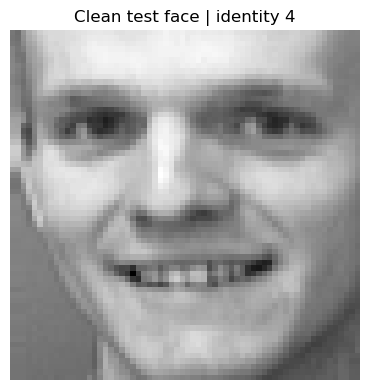

In [124]:
selected_clean_face = x_test_clean_q2d[selected_test_position].reshape(64, 64)
plt.figure(figsize=(4, 4))
plt.imshow(selected_clean_face, cmap="gray")
plt.title(f"Clean test face | identity {selected_true_class}")
plt.axis("off")
plt.tight_layout()
plt.show()

#### Selected test face — masked image

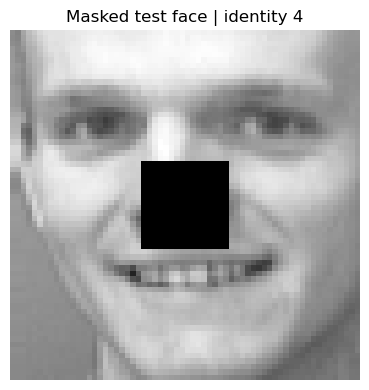

In [125]:
selected_masked_face = x_test_masked_q2d[selected_test_position].reshape(64, 64)
plt.figure(figsize=(4, 4))
plt.imshow(selected_masked_face, cmap="gray")
plt.title(f"Masked test face | identity {selected_true_class}")
plt.axis("off")
plt.tight_layout()
plt.show()

# Q3(a).

In [126]:
q3_repetitions = 30
q3_classes = np.unique(y_train)
q3_K = len(q3_classes)
q3_rng = np.random.default_rng(SEED + 3000)

In [127]:
q3_class_positions = {}
for label in q3_classes:
    positions = np.flatnonzero(y_train == label)
    if len(positions) != 6:
        raise ValueError("Each identity must have exactly six original training images.")
    q3_class_positions[label] = positions

In [128]:
q3_resample_indices = []
for repetition in range(q3_repetitions):
    repetition_indices = []
    for label in q3_classes:
        selected_positions = q3_rng.choice(
            q3_class_positions[label],
            size=6,
            replace=True
        )
        repetition_indices.extend(selected_positions)
    q3_resample_indices.append(np.asarray(repetition_indices, dtype=int))

In [129]:
print("Number of resampled training sets:", len(q3_resample_indices))
print("Training samples in each resampled set:", len(q3_resample_indices[0]))
print("Number of fixed clean test images:", len(x_test))

Number of resampled training sets: 30
Training samples in each resampled set: 240
Number of fixed clean test images: 80


In [130]:
q3_tree_params = best_tree.get_params().copy()
q3_bagging_B = int(final_B)
q3_boosting_depth = int(best_samme_depth)
q3_boosting_rounds = int(best_samme_rounds)
q3_random_error_threshold = 1 - 1 / q3_K

In [131]:
print("Single-tree parameters:", q3_tree_params)
print("Final bagging learners:", q3_bagging_B)
print("Selected SAMME depth:", q3_boosting_depth)
print("Selected SAMME rounds:", q3_boosting_rounds)

Single-tree parameters: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 4, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 26008, 'splitter': 'best'}
Final bagging learners: 100
Selected SAMME depth: 4
Selected SAMME rounds: 100


In [132]:
def q3_tree_probabilities(model, X_eval):
    raw_probabilities = model.predict_proba(X_eval)
    aligned_probabilities = np.zeros((len(X_eval), q3_K))
    class_columns = np.searchsorted(q3_classes, model.classes_)
    aligned_probabilities[:, class_columns] = raw_probabilities
    return aligned_probabilities

In [133]:
def q3_bagging_probabilities(X_fit, y_fit, X_eval, repetition_number):
    votes = np.zeros((len(X_eval), q3_K), dtype=float)
    n_samples = len(X_fit)
    bootstrap_rng = np.random.default_rng(SEED + 400000 + repetition_number)

    for learner_number in range(q3_bagging_B):
        bootstrap_indices = bootstrap_rng.integers(
            0, n_samples, size=n_samples
        )
        learner_params = q3_tree_params.copy()
        learner_params["random_state"] = SEED + 500000 + learner_number
        learner = DecisionTreeClassifier(**learner_params)
        learner.fit(X_fit[bootstrap_indices], y_fit[bootstrap_indices])
        predictions = learner.predict(X_eval)
        columns = np.searchsorted(q3_classes, predictions)
        votes[np.arange(len(X_eval)), columns] += 1

    return votes / q3_bagging_B

In [134]:
def q3_samme_probabilities(X_fit, y_fit, X_eval):
    sample_weights = np.ones(len(y_fit), dtype=float) / len(y_fit)
    class_scores = np.zeros((len(X_eval), q3_K), dtype=float)
    total_learner_weight = 0.0

    for round_number in range(1, q3_boosting_rounds + 1):
        learner = DecisionTreeClassifier(
            max_depth=q3_boosting_depth,
            random_state=SEED + q3_boosting_depth * 1000 + round_number
        )
        learner.fit(X_fit, y_fit, sample_weight=sample_weights)
        train_predictions = learner.predict(X_fit)
        incorrect = train_predictions != y_fit
        weighted_error = np.sum(sample_weights * incorrect)

        if weighted_error >= q3_random_error_threshold:
            break

        if np.isclose(weighted_error, 0.0):
            perfect_predictions = learner.predict(X_eval)
            perfect_columns = np.searchsorted(q3_classes, perfect_predictions)
            perfect_probabilities = np.zeros((len(X_eval), q3_K), dtype=float)
            perfect_probabilities[np.arange(len(X_eval)), perfect_columns] = 1.0
            return perfect_probabilities

        learner_weight = (
            np.log((1 - weighted_error) / weighted_error)
            + np.log(q3_K - 1)
        )

        if not np.isfinite(learner_weight) or learner_weight <= 0:
            break

        eval_predictions = learner.predict(X_eval)
        eval_columns = np.searchsorted(q3_classes, eval_predictions)
        class_scores[np.arange(len(X_eval)), eval_columns] += learner_weight
        total_learner_weight += learner_weight

        sample_weights *= np.exp(learner_weight * incorrect)
        weight_sum = np.sum(sample_weights)
        if weight_sum <= 0 or not np.isfinite(weight_sum):
            break
        sample_weights /= weight_sum

    if total_learner_weight == 0:
        return np.full((len(X_eval), q3_K), 1 / q3_K)

    return class_scores / total_learner_weight

In [135]:
q3_probability_runs = {
    "Single tree": [],
    "Bagging": [],
    "SAMME boosting": []
}

In [136]:
q3_accuracy_runs = {
    "Single tree": [],
    "Bagging": [],
    "SAMME boosting": []
}

In [137]:
for repetition_number, resample_indices in enumerate(q3_resample_indices, start=1):
    x_resampled = x_train[resample_indices]
    y_resampled = y_train[resample_indices]

    single_tree_params = q3_tree_params.copy()
    single_tree_params["random_state"] = SEED
    resampled_tree = Deci+sionTreeClassifier(**single_tree_params)
    resampled_tree.fit(x_resampled, y_resampled)
    single_tree_probs = q3_tree_probabilities(resampled_tree, x_test)

    bagging_probs = q3_bagging_probabilities(
        x_resampled,
        y_resampled,
        x_test,
        repetition_number
    )

    boosting_probs = q3_samme_probabilities(
        x_resampled,
        y_resampled,
        x_test
    )

    current_probabilities = {
        "Single tree": single_tree_probs,
        "Bagging": bagging_probs,
        "SAMME boosting": boosting_probs
    }

    for model_name, probability_vectors in current_probabilities.items():
        q3_probability_runs[model_name].append(probability_vectors)
        predicted_labels = q3_classes[np.argmax(probability_vectors, axis=1)]
        q3_accuracy_runs[model_name].append(
            accuracy_score(y_test, predicted_labels)
        )

    if repetition_number % 5 == 0:
        print("Completed repetitions:", repetition_number, "of", q3_repetitions)

Completed repetitions: 5 of 30
Completed repetitions: 10 of 30
Completed repetitions: 15 of 30
Completed repetitions: 20 of 30
Completed repetitions: 25 of 30
Completed repetitions: 30 of 30


In [138]:
q3_probability_runs = {
    model_name: np.stack(probability_vectors, axis=0)
    for model_name, probability_vectors in q3_probability_runs.items()
}

In [139]:
q3_test_one_hot = (
    y_test[:, np.newaxis] == q3_classes[np.newaxis, :]
).astype(float)

In [140]:
q3_summary_rows = []

In [141]:
for model_name, probability_runs in q3_probability_runs.items():
    mean_probabilities = np.mean(probability_runs, axis=0)

    bias_squared = np.mean(
        np.sum((mean_probabilities - q3_test_one_hot) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum(
            (probability_runs - mean_probabilities[np.newaxis, :, :]) ** 2,
            axis=2
        )
    )

    repetition_accuracies = np.asarray(q3_accuracy_runs[model_name])

    q3_summary_rows.append({
        "Model": model_name,
        "Measured bias squared": bias_squared,
        "Measured variance": variance,
        "Mean test accuracy": np.mean(repetition_accuracies),
        "Std test accuracy": np.std(repetition_accuracies, ddof=1)
    })

In [142]:
q3_results_df = pd.DataFrame(q3_summary_rows)
display(q3_results_df.round(4))

,Model,Measured bias squared,Measured variance,Mean test accuracy,Std test accuracy
0,Single tree,0.4090,0.6566,0.4671,0.0495
1,Bagging,0.5322,0.0245,0.7679,0.0385
2,SAMME boosting,0.8801,0.0180,0.2908,0.0754


In [143]:
q3_accuracy_df = pd.DataFrame({
    "Repetition": np.arange(1, q3_repetitions + 1),
    "Single tree": q3_accuracy_runs["Single tree"],
    "Bagging": q3_accuracy_runs["Bagging"],
    "SAMME boosting": q3_accuracy_runs["SAMME boosting"]
})

In [144]:
display(q3_accuracy_df.round(4))

,Repetition,Single tree,Bagging,SAMME boosting
0,1,0.5000,0.8125,0.3500
1,2,0.4750,0.7625,0.2750
2,3,0.5250,0.7750,0.2125
3,4,0.5375,0.7500,0.3500
4,5,0.4125,0.7750,0.3875
5,6,0.3750,0.7625,0.3875
6,7,0.5000,0.7125,0.1875
7,8,0.5125,0.7500,0.2500
8,9,0.3625,0.7750,0.2500
9,10,0.4750,0.6875,0.2750


## Q3(b).

In [145]:
if best_depth is None:
    q3b_selected_depth = int(best_tree.tree_.max_depth)
    q3b_selected_depth_note = "Q1(a) selected max_depth=None; using the fitted tree's realized depth as the selected-depth comparison."
else:
    q3b_selected_depth = int(best_depth)
    q3b_selected_depth_note = "Using the numeric Q1(a) selected max_depth."

In [146]:
q3b_shallow_depth = 2
if q3b_shallow_depth >= q3b_selected_depth:
    q3b_shallow_depth = max(1, q3b_selected_depth - 1)

q3b_deep_depth = max(16, 2 * q3b_selected_depth)
if q3b_deep_depth <= q3b_selected_depth:
    q3b_deep_depth = q3b_selected_depth + 5

In [147]:
q3b_depth_settings = [
    ("Shallow", q3b_shallow_depth),
    ("Selected", q3b_selected_depth),
    ("Much deeper", q3b_deep_depth)
]

q3b_min_samples_leaf = int(best_tree.get_params()["min_samples_leaf"])
q3b_bagging_B = 100

In [149]:
print(q3b_selected_depth_note)
print("Selected min_samples_leaf:", q3b_min_samples_leaf)
print("Depth settings:", q3b_depth_settings)
print("Bagged trees at each depth:", q3b_bagging_B)
print("Resampling repetitions:", len(q3_resample_indices))

Q1(a) selected max_depth=None; using the fitted tree's realized depth as the selected-depth comparison.
Selected min_samples_leaf: 4
Depth settings: [('Shallow', 2), ('Selected', 34), ('Much deeper', 68)]
Bagged trees at each depth: 100
Resampling repetitions: 30


In [150]:
q3b_single_probability_runs = {label: [] for label, depth in q3b_depth_settings}
q3b_single_accuracy_runs = {label: [] for label, depth in q3b_depth_settings}

In [151]:
for repetition_number, resample_indices in enumerate(q3_resample_indices, start=1):
    x_resampled = x_train[resample_indices]
    y_resampled = y_train[resample_indices]

    for label, depth in q3b_depth_settings:
        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=q3b_min_samples_leaf,
            random_state=SEED + 610000 + repetition_number
        )
        tree.fit(x_resampled, y_resampled)
        probabilities = q3_tree_probabilities(tree, x_test)
        predictions = q3_classes[np.argmax(probabilities, axis=1)]

        q3b_single_probability_runs[label].append(probabilities)
        q3b_single_accuracy_runs[label].append(
            accuracy_score(y_test, predictions)
        )

    if repetition_number % 5 == 0:
        print("Single-tree repetitions completed:", repetition_number, "of", len(q3_resample_indices))

Single-tree repetitions completed: 5 of 30
Single-tree repetitions completed: 10 of 30
Single-tree repetitions completed: 15 of 30
Single-tree repetitions completed: 20 of 30
Single-tree repetitions completed: 25 of 30
Single-tree repetitions completed: 30 of 30


In [153]:
q3b_single_probability_runs = {
    label: np.stack(runs, axis=0)
    for label, runs in q3b_single_probability_runs.items()
}

In [154]:
q3b_bagging_probability_runs = {label: [] for label, depth in q3b_depth_settings}
q3b_bagging_accuracy_runs = {label: [] for label, depth in q3b_depth_settings}

In [155]:
for repetition_number, resample_indices in enumerate(q3_resample_indices, start=1):
    x_resampled = x_train[resample_indices]
    y_resampled = y_train[resample_indices]
    n_resampled = len(y_resampled)

    bootstrap_rng = np.random.default_rng(SEED + 720000 + repetition_number)
    shared_bootstrap_samples = [
        bootstrap_rng.integers(0, n_resampled, size=n_resampled)
        for learner_number in range(q3b_bagging_B)
    ]

    for label, depth in q3b_depth_settings:
        votes = np.zeros((len(x_test), q3_K), dtype=float)

        for learner_number, bootstrap_indices in enumerate(shared_bootstrap_samples):
            learner = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=q3b_min_samples_leaf,
                random_state=(
                    SEED + 800000 + repetition_number * 10000 + learner_number
                )
            )
            learner.fit(
                x_resampled[bootstrap_indices],
                y_resampled[bootstrap_indices]
            )
            predictions = learner.predict(x_test)
            columns = np.searchsorted(q3_classes, predictions)
            votes[np.arange(len(x_test)), columns] += 1

        probabilities = votes / q3b_bagging_B
        predicted_labels = q3_classes[np.argmax(probabilities, axis=1)]

        q3b_bagging_probability_runs[label].append(probabilities)
        q3b_bagging_accuracy_runs[label].append(
            accuracy_score(y_test, predicted_labels)
        )

    if repetition_number % 5 == 0:
        print("Bagging repetitions completed:", repetition_number, "of", len(q3_resample_indices))

Bagging repetitions completed: 5 of 30
Bagging repetitions completed: 10 of 30
Bagging repetitions completed: 15 of 30
Bagging repetitions completed: 20 of 30
Bagging repetitions completed: 25 of 30
Bagging repetitions completed: 30 of 30


In [156]:
q3b_bagging_probability_runs = {
    label: np.stack(runs, axis=0)
    for label, runs in q3b_bagging_probability_runs.items()
}

#### All 100-tree bagging depth experiments completed.

In [157]:
q3b_test_one_hot = (
    y_test[:, np.newaxis] == q3_classes[np.newaxis, :]
).astype(float)

In [158]:
def q3b_measure(probability_runs, accuracy_runs):
    mean_probabilities = np.mean(probability_runs, axis=0)
    bias_squared = np.mean(
        np.sum((mean_probabilities - q3b_test_one_hot) ** 2, axis=1)
    )
    variance = np.mean(
        np.sum(
            (probability_runs - mean_probabilities[np.newaxis, :, :]) ** 2,
            axis=2
        )
    )
    accuracies = np.asarray(accuracy_runs, dtype=float)
    return {
        "Bias squared": bias_squared,
        "Variance": variance,
        "Mean test accuracy": np.mean(accuracies),
        "Std test accuracy": np.std(accuracies, ddof=1)
    }

In [159]:
q3b_metric_results = {}
q3b_summary_rows = []

for label, depth in q3b_depth_settings:
    single_metrics = q3b_measure(
        q3b_single_probability_runs[label],
        q3b_single_accuracy_runs[label]
    )
    bagging_metrics = q3b_measure(
        q3b_bagging_probability_runs[label],
        q3b_bagging_accuracy_runs[label]
    )

    q3b_metric_results[(label, "Single tree")] = single_metrics
    q3b_metric_results[(label, "Bagging (100 trees)")] = bagging_metrics

    q3b_summary_rows.append({
        "Depth setting": label,
        "max_depth": depth,
        "Model": "Single tree",
        **single_metrics
    })
    q3b_summary_rows.append({
        "Depth setting": label,
        "max_depth": depth,
        "Model": "Bagging (100 trees)",
        **bagging_metrics
    })

In [160]:
q3b_summary_df = pd.DataFrame(q3b_summary_rows)
display(q3b_summary_df.round(4))

,Depth setting,max_depth,Model,Bias squared,Variance,Mean test accuracy,Std test accuracy
0,Shallow,2,Single tree,0.9092,0.0466,0.0629,0.0116
1,Shallow,2,Bagging (100 trees),0.9296,0.0105,0.1546,0.0661
2,Selected,34,Single tree,0.3886,0.5964,0.4812,0.0539
3,Selected,34,Bagging (100 trees),0.5330,0.0247,0.7683,0.0436
4,Much deeper,68,Single tree,0.3750,0.6376,0.4938,0.0542
5,Much deeper,68,Bagging (100 trees),0.5323,0.0247,0.7671,0.0424


In [161]:
q3b_reduction_rows = []

for label, depth in q3b_depth_settings:
    single_metrics = q3b_metric_results[(label, "Single tree")]
    bagging_metrics = q3b_metric_results[(label, "Bagging (100 trees)")]

    single_variance = single_metrics["Variance"]
    bagging_variance = bagging_metrics["Variance"]
    variance_reduction = single_variance - bagging_variance
    variance_reduction_pct = (
        100 * variance_reduction / single_variance
        if single_variance > 0 else np.nan
    )

    q3b_reduction_rows.append({
        "Depth setting": label,
        "max_depth": depth,
        "Single-tree variance": single_variance,
        "Bagging variance": bagging_variance,
        "Variance removed": variance_reduction,
        "Variance reduction (%)": variance_reduction_pct,
        "Single-tree bias squared": single_metrics["Bias squared"],
        "Bagging bias squared": bagging_metrics["Bias squared"],
        "Change in bias squared": (
            bagging_metrics["Bias squared"] - single_metrics["Bias squared"]
        )
    })

In [162]:
q3b_reduction_df = pd.DataFrame(q3b_reduction_rows)
display(q3b_reduction_df.round(4))

,Depth setting,max_depth,Single-tree variance,Bagging variance,Variance removed,Variance reduction (%),Single-tree bias squared,Bagging bias squared,Change in bias squared
0,Shallow,2,0.0466,0.0105,0.0361,77.4552,0.9092,0.9296,0.0204
1,Selected,34,0.5964,0.0247,0.5717,95.8611,0.3886,0.5330,0.1444
2,Much deeper,68,0.6376,0.0247,0.6129,96.1318,0.3750,0.5323,0.1574


In [163]:
q3b_plot_labels = [label for label, depth in q3b_depth_settings]
q3b_single_bias = [q3b_metric_results[(label, "Single tree")]["Bias squared"] for label in q3b_plot_labels]
q3b_bagging_bias = [q3b_metric_results[(label, "Bagging (100 trees)")]["Bias squared"] for label in q3b_plot_labels]

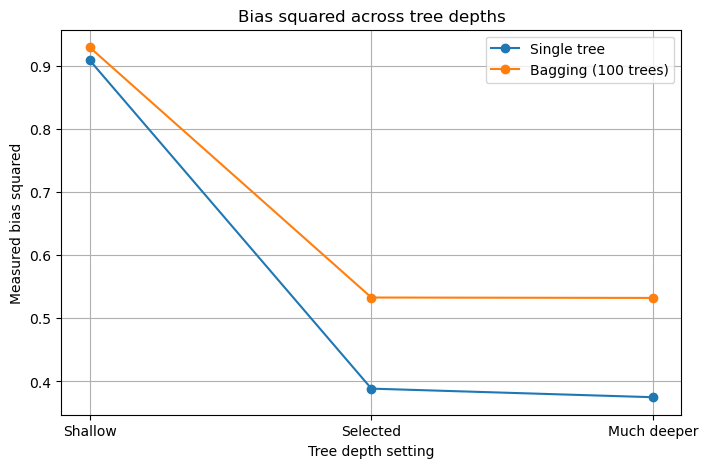

In [164]:
plt.figure(figsize=(8, 5))
plt.plot(q3b_plot_labels, q3b_single_bias, marker="o", label="Single tree")
plt.plot(q3b_plot_labels, q3b_bagging_bias, marker="o", label="Bagging (100 trees)")
plt.xlabel("Tree depth setting")
plt.ylabel("Measured bias squared")
plt.title("Bias squared across tree depths")
plt.legend()
plt.grid(True)
plt.show()

In [165]:
q3b_single_variance = [q3b_metric_results[(label, "Single tree")]["Variance"] for label in q3b_plot_labels]
q3b_bagging_variance = [q3b_metric_results[(label, "Bagging (100 trees)")]["Variance"] for label in q3b_plot_labels]

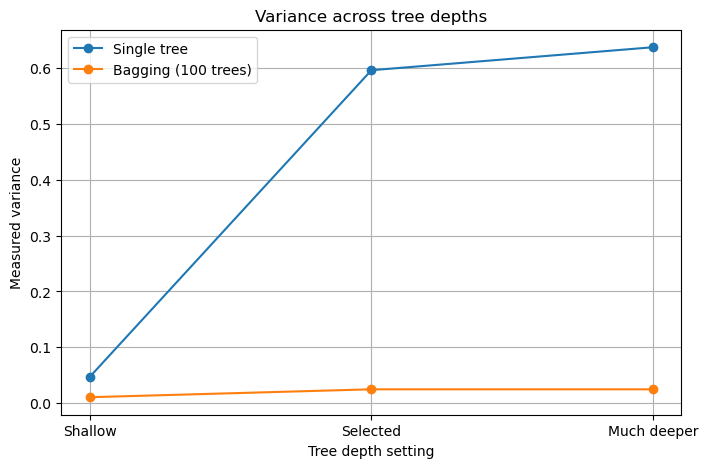

In [166]:
plt.figure(figsize=(8, 5))
plt.plot(q3b_plot_labels, q3b_single_variance, marker="o", label="Single tree")
plt.plot(q3b_plot_labels, q3b_bagging_variance, marker="o", label="Bagging (100 trees)")
plt.xlabel("Tree depth setting")
plt.ylabel("Measured variance")
plt.title("Variance across tree depths")
plt.legend()
plt.grid(True)
plt.show()

## Q3(c).

In [181]:
q3b_single_leaf_runs = {
    label: [] for label, depth in q3b_depth_settings
}

q3b_bagging_leaf_runs = {
    label: [] for label, depth in q3b_depth_settings
}

q3b_bagging_disagreement_runs = {
    label: [] for label, depth in q3b_depth_settings
}


In [182]:
diagnostic_rep = 1

resample_indices = q3_resample_indices[diagnostic_rep - 1]

In [183]:
x_diag = x_train[resample_indices]
y_diag = y_train[resample_indices]

n_diag = len(y_diag)

In [184]:
bootstrap_rng = np.random.default_rng(
    SEED + 720000 + diagnostic_rep
)

shared_bootstrap_samples = [
    bootstrap_rng.integers(0, n_diag, size=n_diag)
    for _ in range(100)
]

In [185]:
q3c_rows = []

In [186]:
for label, depth in q3b_depth_settings:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=q3b_min_samples_leaf,
        random_state=SEED + 610000 + diagnostic_rep
    )

    tree.fit(x_diag, y_diag)

    leaf_ids = tree.apply(x_diag)

    _, counts = np.unique(
        leaf_ids,
        return_counts=True
    )

    q3b_single_leaf_runs[label].append({
        "Number of leaves": len(counts),
        "Mean samples per leaf": np.mean(counts),
        "Singleton leaf fraction": np.mean(counts == 1)
    })

In [187]:
for label, depth in q3b_depth_settings:

    tree_predictions = []

    for learner_number, bootstrap_indices in enumerate(
        shared_bootstrap_samples
    ):

        learner = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=q3b_min_samples_leaf,
            random_state=(
                SEED + 800000 +
                diagnostic_rep * 10000 +
                learner_number
            )
        )

        x_boot = x_diag[bootstrap_indices]
        y_boot = y_diag[bootstrap_indices]

        learner.fit(x_boot, y_boot)

        leaf_ids = learner.apply(x_boot)

        _, counts = np.unique(
            leaf_ids,
            return_counts=True
        )

        q3b_bagging_leaf_runs[label].append({
            "Number of leaves": len(counts),
            "Mean samples per leaf": np.mean(counts),
            "Singleton leaf fraction": np.mean(counts == 1)
        })

        tree_predictions.append(learner.predict(x_test))

    tree_predictions = np.asarray(tree_predictions)

    class_counts = np.column_stack([
        np.sum(tree_predictions == cls, axis=0)
        for cls in q3_classes
    ])

    total_pairs = 100 * 99 / 2

    agreeing_pairs = np.sum(
        class_counts * (class_counts - 1) / 2,
        axis=1
    )

    disagreement = np.mean(
        1 - agreeing_pairs / total_pairs
    )

    q3b_bagging_disagreement_runs[label].append(
        disagreement
    )

    print(label, "disagreement:", disagreement)

Shallow disagreement: 0.9635732323232326
Selected disagreement: 0.8314242424242424
Much deeper disagreement: 0.830989898989899


In [188]:
diagnostic_summary = []

for label, depth in q3b_depth_settings:
    single_leaf = q3b_single_leaf_runs[label][0]
    bagged_leaf = pd.DataFrame(q3b_bagging_leaf_runs[label]).mean(numeric_only=True)

    diagnostic_summary.append({
        "Depth setting": label,
        "max_depth": depth,
        "Single-tree leaves": single_leaf["Number of leaves"],
        "Single-tree mean samples per leaf": single_leaf["Mean samples per leaf"],
        "Single-tree singleton fraction": single_leaf["Singleton leaf fraction"],
        "Mean bagged-tree leaves": bagged_leaf["Number of leaves"],
        "Mean bagged-tree samples per leaf": bagged_leaf["Mean samples per leaf"],
        "Mean bagged-tree singleton fraction": bagged_leaf["Singleton leaf fraction"],
        "Pairwise disagreement": q3b_bagging_disagreement_runs[label][0]
    })

display(pd.DataFrame(diagnostic_summary).round(4))

,Depth setting,max_depth,Single-tree leaves,Single-tree mean samples per leaf,Single-tree singleton fraction,Mean bagged-tree leaves,Mean bagged-tree samples per leaf,Mean bagged-tree singleton fraction,Pairwise disagreement
0,Shallow,2,3,80.0000,0.0,3.17,76.6000,0.0,0.9636
1,Selected,34,36,6.6667,0.0,39.11,6.1427,0.0,0.8314
2,Much deeper,68,40,6.0000,0.0,39.23,6.1243,0.0,0.8310


## Q3(d).

In [194]:
q3d_accuracy = q2d_results_df.pivot(
    index="Model",
    columns="Test set",
    values="Accuracy"
)

In [195]:
q3d_bias_variance = q3_results_df.set_index("Model")[[
    "Measured bias squared",
    "Measured variance"
]]

In [196]:
q3d_model_order = ["Single tree", "Bagging", "SAMME boosting"]

In [197]:
q3d_final_table = pd.DataFrame(index=q3d_model_order)
q3d_final_table["Clean test accuracy (%)"] = (
    100 * q3d_accuracy.loc[q3d_model_order, "Clean"]
)
q3d_final_table["Masked test accuracy (%)"] = (
    100 * q3d_accuracy.loc[q3d_model_order, "Masked"]
)
q3d_final_table["Bias squared"] = q3d_bias_variance.loc[
    q3d_model_order, "Measured bias squared"
]
q3d_final_table["Variance"] = q3d_bias_variance.loc[
    q3d_model_order, "Measured variance"
]
q3d_final_table.index.name = "Model"

In [198]:
display(q3d_final_table.round(4))

,Clean test accuracy (%),Masked test accuracy (%),Bias squared,Variance
Model,,,,
Single tree,50.0,50.00,0.4090,0.6566
Bagging,85.0,73.75,0.5322,0.0245
SAMME boosting,40.0,45.00,0.8801,0.0180


In [200]:
q3d_accuracy_drop = (
    q3d_final_table["Clean test accuracy (%)"]
    - q3d_final_table["Masked test accuracy (%)"]
)

In [201]:
q3d_lowest_vector_variance_model = q3d_final_table["Variance"].idxmin()
q3d_accuracy_sd = q3_results_df.set_index("Model")["Std test accuracy"]
q3d_lowest_accuracy_sd_model = q3d_accuracy_sd.idxmin()
q3d_most_masking_affected_model = q3d_accuracy_drop.idxmax()

In [202]:
print("Accuracy change after masking (percentage points):")
for model in q3d_model_order:
    print(f"{model}: {q3d_accuracy_drop.loc[model]:.2f}")

print("\nLowest measured prediction-vector variance:", q3d_lowest_vector_variance_model)
print("Lowest standard deviation of accuracy across refits:", q3d_lowest_accuracy_sd_model)
print("Largest aggregate accuracy loss after masking:", q3d_most_masking_affected_model)
print("\nStandard deviation of test accuracy across 30 refits:")
for model in q3d_model_order:
    print(f"{model}: {q3d_accuracy_sd.loc[model]:.4f}")

Accuracy change after masking (percentage points):
Single tree: 0.00
Bagging: 11.25
SAMME boosting: -5.00

Lowest measured prediction-vector variance: SAMME boosting
Lowest standard deviation of accuracy across refits: Bagging
Largest aggregate accuracy loss after masking: Bagging

Standard deviation of test accuracy across 30 refits:
Single tree: 0.0495
Bagging: 0.0385
SAMME boosting: 0.0754


### Saving the Train, Validation and Test Split

In [203]:
np.savez_compressed(
    "olivetti_split_seed_26008.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)